# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Ricerra, Myke Lawrence
- _Student No._: 2024-07203
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure

<img src="figures/11.1.png" alt="Absolute Error Convergence" width=60%>

**Figure 1. Absolute Error Convergence.** Log-log absolute error comparison of the Trapezoid, Simpson's 1/3, and Simpson's 3/8 rules across subinterval counts $N = 10$ to $10^7$ for $f_1$, $f_2$, and $f_3$.

<img src="figures/11.2.png" alt="Monte Carlo Hit-or-Miss Integration" width=60%>

**Figure 2. Monte Carlo Hit-or-Miss Integration.** Monte Carlo area estimation ($N = 10{,}000$) for $f_1(x_1)$, $f_2(x_2)$, and $f_3(x_3)$, showing positive (blue) and negative (red) bounded regions.


### Report discussion

As expected, the error decreases as we increase the number of sample points, as seen in Figure 1. Interestingly, for $f_2(x_2) = -x^2 + 1$, both Simpson's rules immediately dropped to the $10^{-16}$ floor. This is because the function itself is already quadratic, and both Simpson's rules use higher-order polynomials, making their evaluations mathematically exact.

We can arrive at an integration value using Monte Carlo simulation because a definite integral can be framed as a geometric probability (the ratio of points landing under the curve to the total points within a known bounding box). As a direct consequence of the Law of Large Numbers, simply ramping up the number of random samples $N$ guarantees that these sample ratios converge to the true integral. With 10,000 sample points, the signed and total areas came close to the actual values up to the tenths or hundredths place. However, when we need high precision, Newton-Cotes methods like the Trapezoidal and Simpson's rules are far more suitable, as they converge orders of magnitude faster ($O(N^{-2})$ to $O(N^{-4})$) than Monte Carlo's $O(N^{-1/2})$ rate. While Newton-Cotes dominates on simple curves, that efficiency completely vanishes with irregular geometries and discontinuous functions, which is exactly where Monte Carlo shines.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem:

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo)

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output:
1. total area bounded by the curve, x-axis, and x bounds
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures):
For each function, plot the following:

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**:
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
inte1, _ = quad(lambda x: np.sqrt((3-2*x)*(3+2*x)), 0, 3/2)
inte2, _ = quad(lambda x: (1-x)*(1+x), -2.0, 2.0)
inte3, _ = quad(lambda x: np.cos(x) * np.sqrt(x), 0.0, np.pi)

tot_area1, _ = quad(lambda x: np.sqrt((3-2*x)*(3+2*x)), 0, 3/2)
tot_area2, _ = quad(lambda x: np.abs((1 - x)*(1 + x)), -2.0, 2.0, points=[-1.0, 1.0])
tot_area3, _ = quad(lambda x: np.abs(np.cos(x) * np.sqrt(x)), 0.0, np.pi, points=[np.pi / 2])


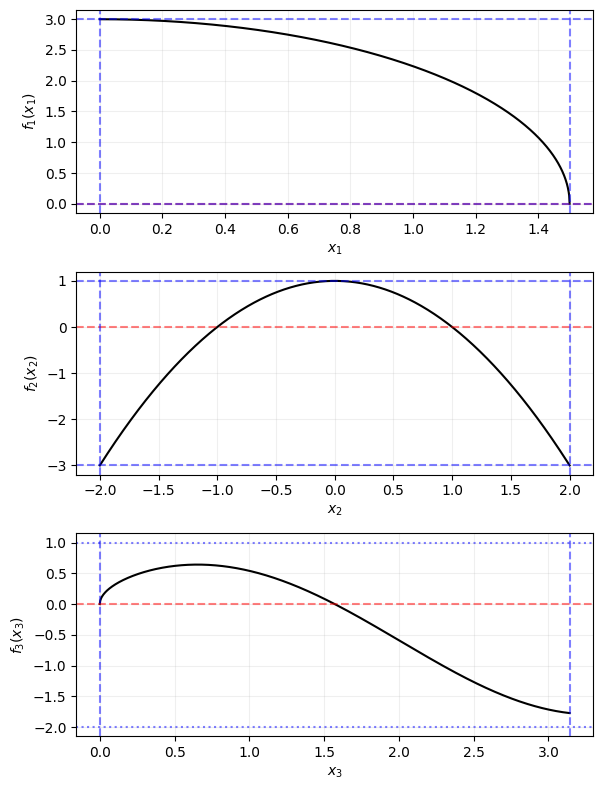

In [4]:
# Each entry: (func, x_min, x_max, roots, exact_area, y_bounds, linestyle)
CASES = [
    (lambda x: np.sqrt((3-2*x)*(3+2*x)), 0.0, 1.5, [], inte1, (0.0, 3.0), "--"),
    (lambda x: (1 - x)*(1 + x), -2.0, 2.0, [-1.0, 1.0], inte2, (-3.0, 1.0), "--"),
    (lambda x: np.cos(x) * np.sqrt(x), 0.0, np.pi, [np.pi / 2], inte3, (-2.0, 1.0), ":"),
]
CASES_TOT = [
    (lambda x: np.sqrt((3-2*x)*(3+2*x)), 0.0, 1.5, [], tot_area1, (0.0, 3.0), "--"),
    (lambda x: np.abs((1 - x)*(1 + x)), -2.0, 2.0, [-1.0, 1.0], tot_area2, (-3.0, 1.0), "--"),
    (lambda x: np.abs(np.cos(x) * np.sqrt(x)), 0.0, np.pi, [np.pi / 2], tot_area3, (-2.0, 1.0), ":"),
]

RESO = 1024
RESOS = np.logspace(1, 7, num=10, dtype=int)


def plot_cases(cases, reso: int) -> None:
    fig, axes = plt.subplots(len(cases), 1, figsize=(6, 8))

    for idx, (func, a, b, _, _, y_bounds, ls) in enumerate(cases):
        ax = axes[idx]
        dom = np.linspace(a, b, reso)

        ax.plot(dom, func(dom), color="black")
        ax.axhline(y=0, linestyle="--", color="r", alpha=0.5)
        ax.axvline(x=a, linestyle="--", color="b", alpha=0.5)
        ax.axvline(x=b, linestyle="--", color="b", alpha=0.5)

        for y_val in y_bounds:
            ax.axhline(y=y_val, linestyle=ls, color="b", alpha=0.5)

        ax.set_xlabel(rf"$x_{idx + 1}$")
        ax.set_ylabel(rf"$f_{idx + 1}(x_{idx + 1})$")
        ax.grid(True, alpha=0.2)

    fig.tight_layout()
    plt.show()

plot_cases(CASES, RESO)

In [5]:
# Each entry: (func, x_min, x_max, Ns, weight, scale)
def sum_weighted(func, a: float, b: float, n: int, weights: np.ndarray, scale: float) -> float:
    h = (b - a) / (n - 1)
    xs = np.linspace(a, b, n)
    return scale * h * float(np.sum(weights * func(xs)))

# Each entry: (func, x_min, x_max, Ns)
def trapezoid(func, a: float, b: float, n: int) -> float:
    weights = np.ones(n)
    weights[[0, -1]] = 0.5
    return sum_weighted(func, a, b, n, weights, scale=1.0)

def simpson13(func, a: float, b: float, n: int) -> float:
    if (n - 1) % 2 != 0:
      n += 1
    weights = np.full(n, 2.0)
    weights[1::2] = 4.0
    weights[[0, -1]] = 1.0
    return sum_weighted(func, a, b, n, weights, scale=1 / 3)

def simpson38(func, a: float, b: float, n: int) -> float:
    if (n - 1) % 3 != 0:
        n += 3 - (n - 1) % 3
    weights = np.full(n, 3.0)
    weights[0::3] = 2.0
    weights[[0, -1]] = 1.0
    return sum_weighted(func, a, b, n, weights, scale=3 / 8)

METHODS = {
    "Trapezoid": trapezoid,
    "Simpson 1/3": simpson13,
    "Simpson 3/8": simpson38,
}

# Each entry: (method, func, x_min, x_max, roots, Ns)
def integrate_piecewise(method, func, a: float, b: float, roots: list, n: int) -> float:
    breakpoints = [a, *roots, b]
    total_len = b - a
    total_area = 0.0

    for x0, x1 in zip(breakpoints[:-1], breakpoints[1:]):
        sub_intervals = max(3, int(round((n - 1) * (x1 - x0) / total_len)))
        total_area += abs(method(func, x0, x1, sub_intervals + 1))

    return total_area

# Each entry: (cases, method, total_area?)
def evaluate_methods(cases, methods, reso: int, total_area: bool = False) -> None:
    for name, method in methods.items():
        print(f"--- {name} ---")
        for idx, (func, a, b, roots, exact_area, _, _) in enumerate(cases):
            if total_area:
                area = integrate_piecewise(method, func, a, b, roots, reso)
            else:
                area = method(func, a, b, reso)

            rel_error = np.abs(exact_area - area) / np.abs(exact_area)
            print(f"Case {idx + 1}: Area = {area:.8f}; Rel. Error = {rel_error:.3e}")

print("Total Area")
evaluate_methods(CASES_TOT, METHODS, RESO, total_area=True)
print("\nSigned Area (Integral)")
evaluate_methods(CASES, METHODS, RESO, total_area=False)

Total Area
--- Trapezoid ---
Case 1: Area = 3.53425130; Rel. Error = 1.144e-05
Case 2: Area = 4.00000000; Rel. Error = 0.000e+00
Case 3: Area = 2.30286990; Rel. Error = 1.610e-05
--- Simpson 1/3 ---
Case 1: Area = 3.53427597; Rel. Error = 4.461e-06
Case 2: Area = 4.00000000; Rel. Error = 0.000e+00
Case 3: Area = 2.30289318; Rel. Error = 5.991e-06
--- Simpson 3/8 ---
Case 1: Area = 3.53427251; Rel. Error = 5.440e-06
Case 2: Area = 4.00000000; Rel. Error = 0.000e+00
Case 3: Area = 2.30289023; Rel. Error = 7.273e-06

Signed Area (Integral)
--- Trapezoid ---
Case 1: Area = 3.53425130; Rel. Error = 1.144e-05
Case 2: Area = -1.33334353; Rel. Error = 7.644e-06
Case 3: Area = -0.89486707; Rel. Error = 3.978e-05
--- Simpson 1/3 ---
Case 1: Area = 3.53427597; Rel. Error = 4.461e-06
Case 2: Area = -1.33333333; Rel. Error = 1.665e-16
Case 3: Area = -0.89484527; Rel. Error = 1.542e-05
--- Simpson 3/8 ---
Case 1: Area = 3.53427251; Rel. Error = 5.440e-06
Case 2: Area = -1.33333333; Rel. Error = 0.00

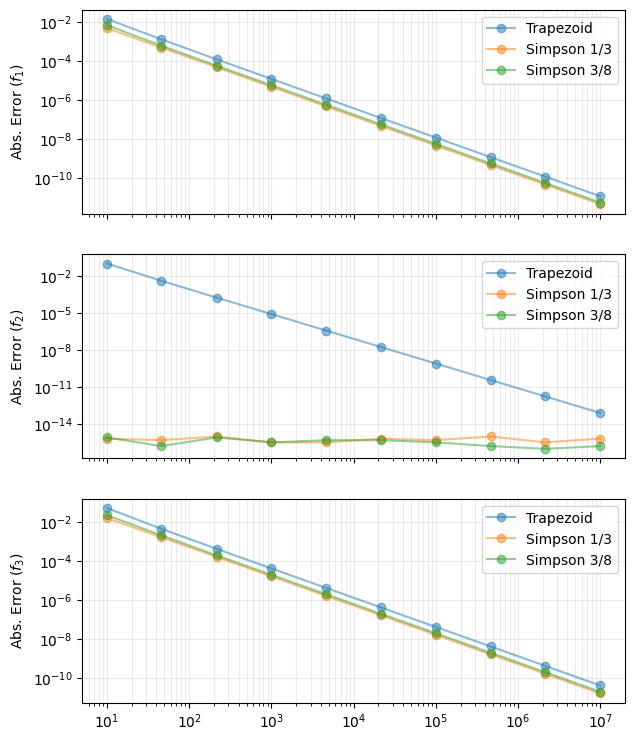

In [6]:
# Each entry: (cases, method, Ns, total_area?)
def plot_error_vs_n(cases, methods, ns, total_area: bool = False) -> None:
    fig, axes = plt.subplots(len(cases), 1, figsize=(7, 9), sharex=True)

    for idx, (func, a, b, roots, exact_area, _, _) in enumerate(cases):
        ax = axes[idx]

        for name, method in methods.items():
            errors = []
            for n in ns:
                if total_area:
                    area = integrate_piecewise(method, func, a, b, roots, int(n))
                else:
                    area = method(func, a, b, int(n))

                abs_error = np.abs(exact_area - area) / np.abs(exact_area)
                errors.append(max(abs_error, 1e-16))

            ax.loglog(ns, errors, marker="o", alpha=0.5, label=name)

        ax.set_ylabel(rf"Abs. Error ($f_{idx + 1}$)")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend()


plot_error_vs_n(CASES, METHODS, RESOS, total_area=False)

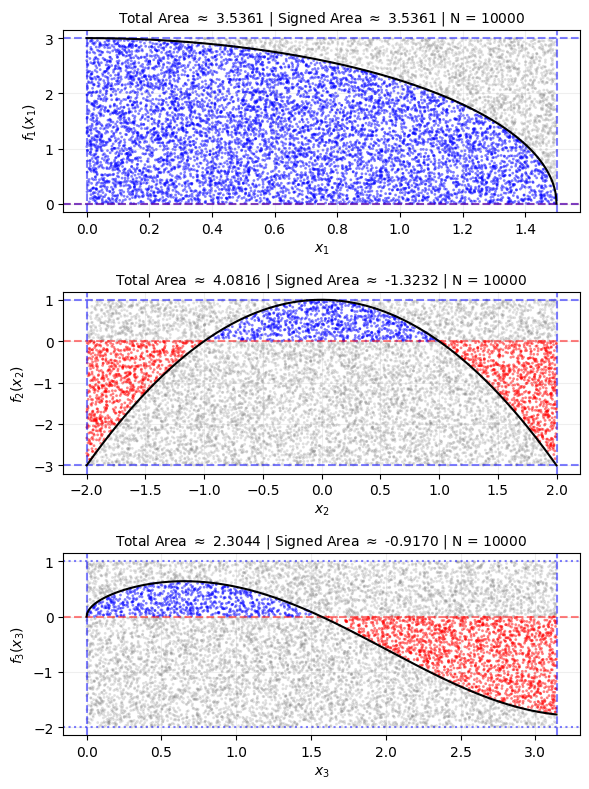

In [7]:
# Each entry: (cases, Ns, Ns - curve, seed -> i used 67 in the figure)
def monte_carlo_cases(cases, n_samples: int, reso: int = 1024, seed: int = None):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(len(cases), 1, figsize=(6, 8))
    axes = np.atleast_1d(axes)
    results = []

    for idx, (func, a, b, _, _, y_bounds, ls) in enumerate(cases):
        ax = axes[idx]
        y_min, y_max = y_bounds
        dom = np.linspace(a, b, reso)

        x = rng.uniform(a, b, size=n_samples)
        y = rng.uniform(y_min, y_max, size=n_samples)
        f_x = func(x)

        pos_hits = (y >= 0) & (y <= f_x)
        neg_hits = (y < 0) & (y >= f_x)
        misses = ~(pos_hits | neg_hits)

        box_area = (b - a) * (y_max - y_min)
        pos_area = box_area * np.mean(pos_hits)
        neg_area = box_area * np.mean(neg_hits)
        total_area = pos_area + neg_area
        signed_area = pos_area - neg_area
        results.append({"total_area": total_area, "signed_area": signed_area})

        ax.scatter(x[misses], y[misses], color="gray", s=4, alpha=0.25, edgecolors="none")
        if np.any(pos_hits):
            ax.scatter(x[pos_hits], y[pos_hits], color="blue", s=4, alpha=0.5, edgecolors="none")
        if np.any(neg_hits):
            ax.scatter(x[neg_hits], y[neg_hits], color="red", s=4, alpha=0.5, edgecolors="none")

        ax.plot(dom, func(dom), color="black", zorder=3)
        ax.axhline(y=0, linestyle="--", color="r", alpha=0.5)
        ax.axvline(x=a, linestyle="--", color="b", alpha=0.5)
        ax.axvline(x=b, linestyle="--", color="b", alpha=0.5)

        for y_val in y_bounds:
            ax.axhline(y=y_val, linestyle=ls, color="b", alpha=0.5)

        ax.set_xlabel(rf"$x_{idx + 1}$")
        ax.set_ylabel(rf"$f_{idx + 1}(x_{idx + 1})$")
        ax.set_title(
            fr"Total Area $\approx$ {total_area:.4f} | Signed Area $\approx$ {signed_area:.4f} | N = {n_samples}",
            fontsize=10,
        )
        ax.grid(True, alpha=0.2)

    fig.tight_layout()
    plt.show()
    return results

mc_results = monte_carlo_cases(CASES, 10000, reso=RESO, seed=67)